<a href="https://colab.research.google.com/github/shubhamraut0209/SWYNEX-Exploratory-Data-Analysis/blob/main/Task_2_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SWYNEX Task 2 — Exploratory Data Analysis (EDA)**

**Dataset:** `ecommerce_retail_transactions_cleaned.csv`  
**Tools:** Python, pandas, matplotlib  
**Goal:** Summarize the dataset, explore trends and patterns, visualize key measures, and document actionable insights.

## Metric definitions
- **Gross sales (estimated):** `quantity × unit_price_usd`
- **Discount amount (estimated):** `gross_sales_usd × discount_percent / 100`
- **Net sales (estimated):** `gross_sales_usd − discount_amount_usd`

These are analytical estimates from the fields available. They do not account for tax, shipping, returns, or other adjustments unless already included in the data. A row is treated as one transaction record; verify the source data's business definition before interpreting the measures as finalized accounting revenue.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Put the cleaned CSV in the same folder as this notebook, or update this path.
DATA_PATH = "ecommerce_retail_transactions_cleaned.csv"
df = pd.read_csv(DATA_PATH)
df.head()


,order_id,customer_id,order_date,product_category,product_name,quantity,unit_price_usd,discount_percent,payment_method,shipping_city,country,order_status,customer_rating
0,ORD011416,CUST00003,2026-04-03,Books,Self-Help Book,3,9.16,5.0,Net Banking,London,United Kingdom,Delivered,5.0
1,ORD000974,CUST00269,2024-10-15,Books,Fiction Novel,1,34.24,5.0,Net Banking,Toronto,Canada,Shipped,NaN
2,ORD000617,CUST02075,2024-06-17,Home & Kitchen,Vacuum Cleaner,2,111.95,15.0,Debit Card,Brisbane,Australia,Shipped,NaN
3,ORD006437,CUST02109,2025-10-16,Beauty,Hair Dryer,1,31.84,0.0,Cash on Delivery,Birmingham,United Kingdom,Delivered,3.0
4,ORD000740,CUST00349,2026-04-06,Home & Kitchen,Non-Stick Pan,2,72.00,0.0,Credit Card,Montreal,Canada,Delivered,NaN


In [ ]:
print("Rows, columns:", df.shape)
print("\\nColumn types:")
print(df.dtypes)
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nDuplicate rows:", df.duplicated().sum())
print("Unique order IDs:", df["order_id"].nunique())
print("Unique customers:", df["customer_id"].nunique())


Rows, columns: (11814, 13)
\nColumn types:
order_id             object
customer_id          object
order_date           object
product_category     object
product_name         object
quantity              int64
unit_price_usd      float64
discount_percent    float64
payment_method       object
shipping_city        object
country              object
order_status         object
customer_rating     float64
dtype: object
\nMissing values:


,missing_count
customer_rating,5968
shipping_city,491
order_date,0
customer_id,0
order_id,0
product_name,0
product_category,0
quantity,0
unit_price_usd,0
payment_method,0


\nDuplicate rows: 0
Unique order IDs: 11814
Unique customers: 3368


In [ ]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["gross_sales_usd"] = df["quantity"] * df["unit_price_usd"]
df["discount_amount_usd"] = df["gross_sales_usd"] * df["discount_percent"] / 100
df["net_sales_usd"] = df["gross_sales_usd"] - df["discount_amount_usd"]
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)

numeric_cols = ["quantity", "unit_price_usd", "discount_percent",
                "gross_sales_usd", "discount_amount_usd", "net_sales_usd",
                "customer_rating"]
display(df[numeric_cols].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
quantity,11814.0,2.06,1.20,1.00,1.00,2.00,3.00,5.00
unit_price_usd,11814.0,61.54,52.47,3.01,22.03,42.80,87.74,249.84
discount_percent,11814.0,6.87,7.13,0.00,0.00,5.00,10.00,25.00
gross_sales_usd,11814.0,127.01,147.09,3.04,34.51,76.38,157.93,1249.20
discount_amount_usd,11814.0,8.68,16.58,0.00,0.00,2.27,10.04,242.42
net_sales_usd,11814.0,118.34,138.23,2.55,31.64,70.42,147.61,1249.20
customer_rating,5846.0,3.90,1.11,1.00,3.00,4.00,5.00,5.00


In [ ]:
# Category summary
category_summary = df.groupby("product_category").agg(
    transactions=("order_id", "count"),
    units=("quantity", "sum"),
    gross_sales_usd=("gross_sales_usd", "sum"),
    discounts_usd=("discount_amount_usd", "sum"),
    net_sales_usd=("net_sales_usd", "sum"),
    avg_rating=("customer_rating", "mean")
).sort_values("net_sales_usd", ascending=False)
display(category_summary.round(2))


,transactions,units,gross_sales_usd,discounts_usd,net_sales_usd,avg_rating
product_category,,,,,,
Electronics,1461,2999,404823.33,27248.68,377574.65,4.00
Home & Kitchen,1517,3179,297017.46,20137.27,276880.19,3.91
Sports,1420,2906,237799.61,16897.66,220901.95,3.90
Fashion,1494,3062,195721.90,13337.09,182384.81,3.90
Toys,1512,3049,150650.24,10016.55,140633.69,3.88
Beauty,1468,3029,95773.18,7016.42,88756.76,3.88
Books,1501,3090,68758.27,4481.40,64276.87,3.85
Grocery,1441,3007,49997.87,3379.70,46618.17,3.88


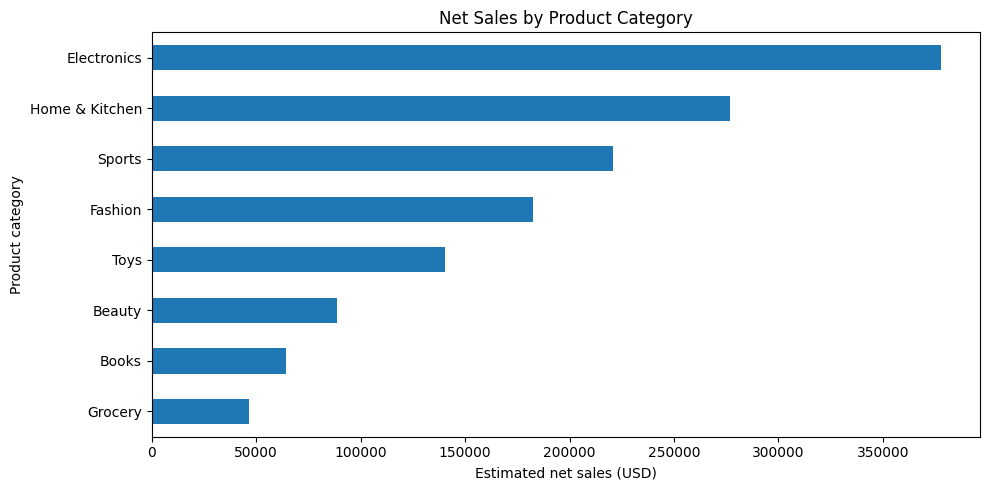

In [ ]:
category_summary["net_sales_usd"].sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("Net Sales by Product Category")
plt.xlabel("Estimated net sales (USD)")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()


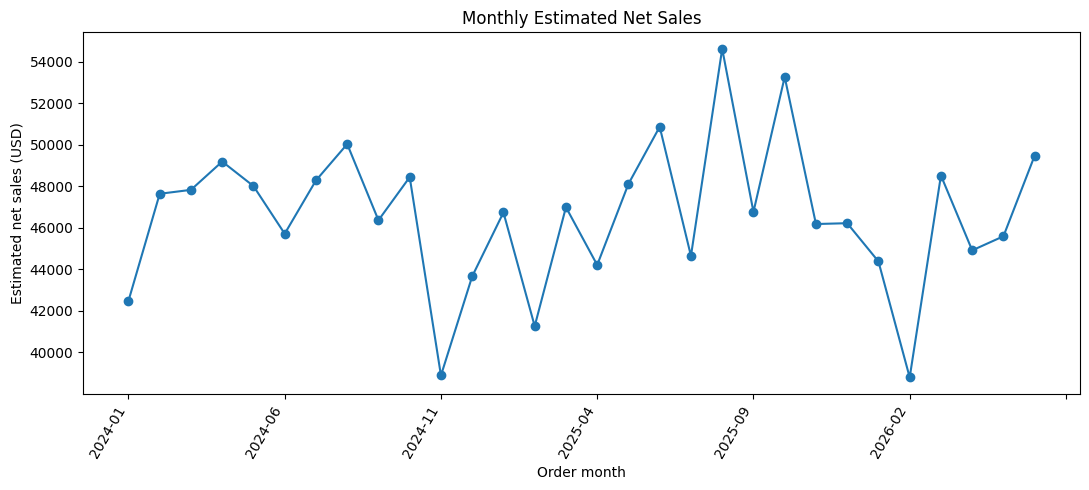

In [ ]:
# Monthly trend
monthly_summary = df.groupby("order_month").agg(
    transactions=("order_id", "count"),
    net_sales_usd=("net_sales_usd", "sum"),
    units=("quantity", "sum")
).reset_index()
monthly_summary.plot(x="order_month", y="net_sales_usd", kind="line", marker="o", figsize=(11, 5), legend=False)
plt.title("Monthly Estimated Net Sales")
plt.xlabel("Order month")
plt.ylabel("Estimated net sales (USD)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


,transactions,net_sales_usd
payment_method,,
Cash on Delivery,2041,235773.30
PayPal,2008,248105.93
Credit Card,2000,235287.41
Net Banking,1990,240733.94
UPI,1897,217535.99
Debit Card,1878,220590.51


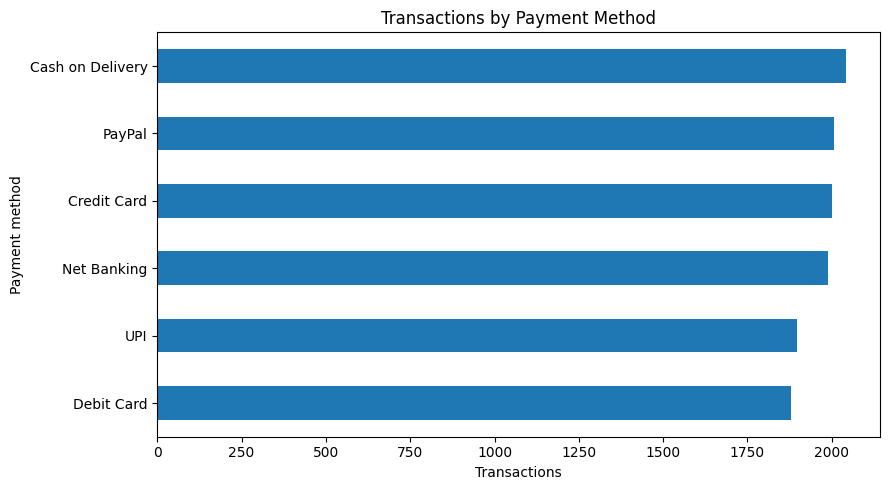

,transactions,net_sales_usd
order_status,,
Delivered,6472,770333.42
Shipped,1797,213224.71
Pending,1370,161735.49
Cancelled,1178,139470.13
Returned,997,113263.32


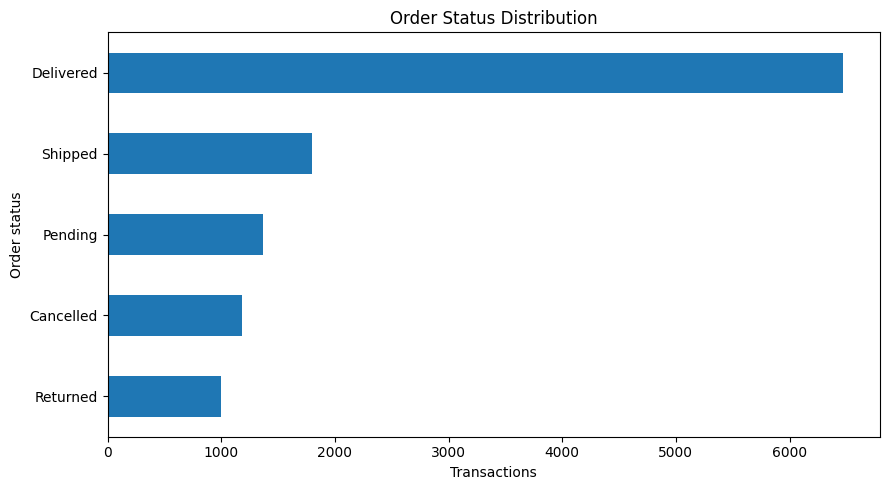

In [ ]:
# Payment method and order status
payment_summary = df.groupby("payment_method").agg(
    transactions=("order_id", "count"),
    net_sales_usd=("net_sales_usd", "sum")
).sort_values("transactions", ascending=False)
display(payment_summary.round(2))
payment_summary["transactions"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Transactions by Payment Method")
plt.xlabel("Transactions")
plt.ylabel("Payment method")
plt.tight_layout()
plt.show()

status_summary = df.groupby("order_status").agg(
    transactions=("order_id", "count"),
    net_sales_usd=("net_sales_usd", "sum")
).sort_values("transactions", ascending=False)
display(status_summary.round(2))
status_summary["transactions"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Order Status Distribution")
plt.xlabel("Transactions")
plt.ylabel("Order status")
plt.tight_layout()
plt.show()


Rated records: 5,846 / 11,814
Missing ratings: 5,968 (50.5%)
Mean rating among rated records: 3.90/5


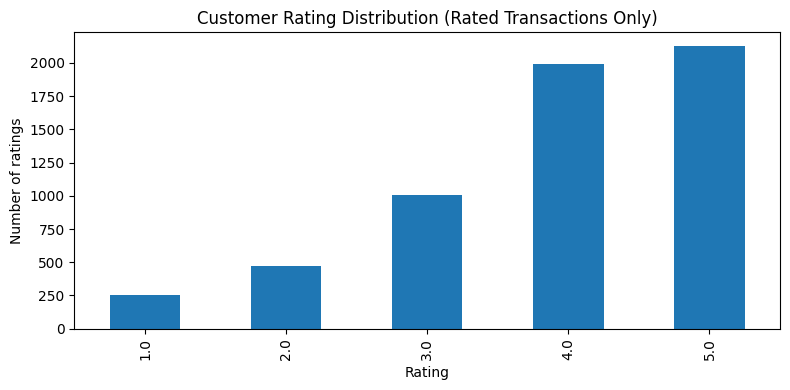

In [ ]:
# Ratings: analyze only records where a rating exists
ratings = df["customer_rating"].dropna()
print(f"Rated records: {len(ratings):,} / {len(df):,}")
print(f"Missing ratings: {df['customer_rating'].isna().sum():,} ({df['customer_rating'].isna().mean()*100:.1f}%)")
print(f"Mean rating among rated records: {ratings.mean():.2f}/5")
ratings.value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.title("Customer Rating Distribution (Rated Transactions Only)")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()


,transactions,net_sales_usd
country,,
United Arab Emirates,1710,210840.68
Germany,1726,202183.26
India,1659,201019.32
Canada,1612,191798.69
Australia,1688,188596.29
United States,1325,155989.46
United Kingdom,1288,152926.00
uk,448,51888.84
usa,358,42784.54


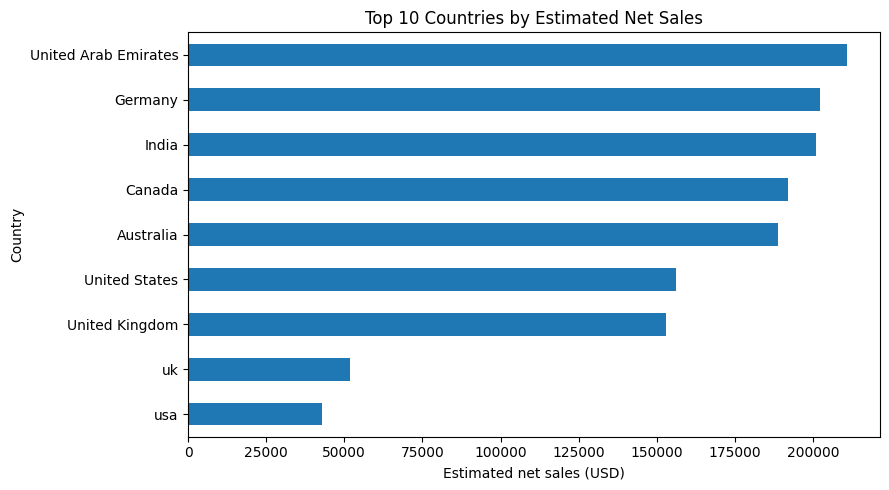

,transactions,units,net_sales_usd
product_name,,,
Power Bank,209,431,54482.82
Bluetooth Speaker,186,422,54190.93
Smartwatch,191,400,50990.00
Cricket Bat,289,615,47358.37
Gaming Mouse,183,374,46811.62
USB-C Cable,175,388,46763.23
Non-Stick Pan,231,516,45964.58
Wireless Earbuds,185,355,45551.51
Dumbbell Set,290,597,43986.09


In [ ]:
# Geographic and product summaries
country_summary = df.groupby("country").agg(
    transactions=("order_id", "count"),
    net_sales_usd=("net_sales_usd", "sum")
).sort_values("net_sales_usd", ascending=False)
display(country_summary.head(10).round(2))
country_summary.head(10).sort_values("net_sales_usd")["net_sales_usd"].plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Countries by Estimated Net Sales")
plt.xlabel("Estimated net sales (USD)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

product_summary = df.groupby("product_name").agg(
    transactions=("order_id", "count"),
    units=("quantity", "sum"),
    net_sales_usd=("net_sales_usd", "sum")
).sort_values("net_sales_usd", ascending=False)
display(product_summary.head(10).round(2))


## Insight checklist
Use the tables and plots above to report at least five evidence-backed insights. For each insight, state the metric, the actual value, why it matters, and a cautious business recommendation.

Remember:
- A high transaction count is not automatically high profitability.
- Ratings describe only the subset with recorded ratings.
- A status distribution is a snapshot unless the dataset's status history is known.
- Missing city data limits city-level comparisons.
- Net sales here are estimated from quantity, unit price, and discount only.
